# Where are America's national parks really crowded?

The National Park Service counts recreation visits per park, each month. Spread over a whole park, the numbers look
gentle: most of a big park is wilderness that few visitors reach. Most visits happen along the scenic roads, the short
trails near them and the visitor facilities. Here each park's **visitor core** was drawn by one written rule from NPS
roads, trails and facilities, and visits are measured per km² of core as well as per km² of park. The shapes in
`data/geometry/` were made in [Plotlay](https://www.getplotlay.com). This notebook reads only `../data`.

In [1]:
import pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
DATA = '../data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
p = pd.read_csv(f'{DATA}/tables/parks.csv'); m = pd.read_csv(f'{DATA}/tables/park_months.csv', parse_dates=['month'])
print(len(p), 'parks;', m.month.nunique(), 'months from', m.month.min().date(), 'to', m.month.max().date())
p[['name', 'state', 'area_km2', 'core_km2', 'core_share_pct', 'visits_2025', 'roads_source']].sort_values('visits_2025', ascending=False)

25 parks; 132 months from 2015-01-01 to 2025-12-01


,name,state,area_km2,core_km2,core_share_pct,visits_2025,roads_source
0,Great Smoky Mountains,"TN, NC",2262.37,228.53,10.10,11527939,NPS
1,Zion,UT,601.80,33.72,5.60,4984525,NPS
2,Yellowstone,"WY, MT, ID",8901.11,313.79,3.53,4762988,NPS
3,Grand Canyon,AZ,4869.39,104.13,2.14,4430653,NPS
4,Yosemite,CA,3026.39,179.55,5.93,4278413,NPS
5,Rocky Mountain,CO,1080.83,93.45,8.65,4171431,NPS
6,Acadia,ME,145.29,75.73,52.13,4079318,NPS
7,Grand Teton,WY,1254.58,135.55,10.80,3800648,NPS
8,Olympic,WA,3717.10,97.49,2.62,3584187,NPS
9,Glacier,MT,4079.65,163.30,4.00,3136557,NPS


## 1. Per km² of park, and per km² of core

A year's visits over the area and 365 days. The four parks with no NPS road data (roads from Census TIGER, every public
street) have cores that read larger and emptier, so they are left out of the ranking.

In [2]:
q = p.assign(per_day_park=p.visits_2025 / p.area_km2 / 365, per_day_core=p.visits_2025 / p.core_km2 / 365)
nps = q[q.roads_source == 'NPS'].copy()
nps['rank_park'] = nps.per_day_park.rank(ascending=False).astype(int); nps['rank_core'] = nps.per_day_core.rank(ascending=False).astype(int)
print('Spearman between the two rankings:', round(nps[['rank_park', 'rank_core']].corr(method='spearman').iloc[0, 1], 2))
nps.sort_values('per_day_core', ascending=False)[['name', 'per_day_park', 'per_day_core', 'rank_park', 'rank_core']].round(1)

Spearman between the two rankings: 0.88


,name,per_day_park,per_day_core,rank_park,rank_core
1,Zion,22.7,405.0,4,1
12,Indiana Dunes,101.1,248.0,1,2
15,Bryce Canyon,37.0,209.7,3,3
6,Acadia,76.9,147.6,2,4
20,Arches,13.4,144.3,6,5
0,Great Smoky Mountains,14.0,138.2,5,6
5,Rocky Mountain,10.6,122.3,7,7
3,Grand Canyon,2.5,116.6,14,8
17,Hawaiʻi Volcanoes,3.3,106.1,12,9
8,Olympic,2.6,100.7,13,10


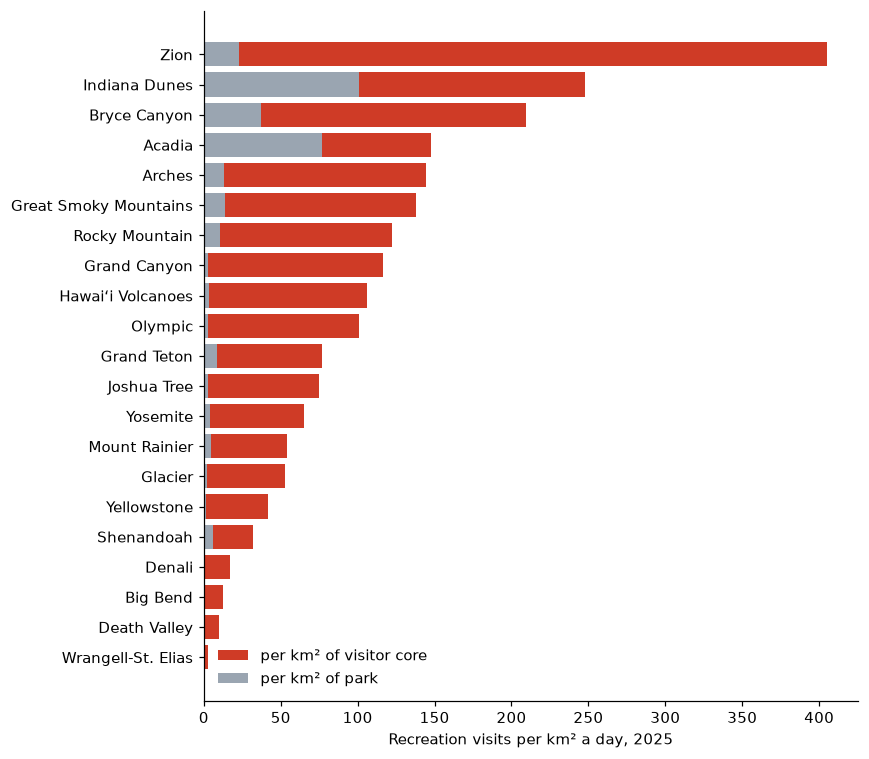

In [3]:
t = nps.sort_values('per_day_core')
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(t.name, t.per_day_core, color='#cf3b26', label='per km² of visitor core')
ax.barh(t.name, t.per_day_park, color='#9aa5b1', label='per km² of park')
ax.set_xlabel('Recreation visits per km² a day, 2025'); ax.legend(frameon=False); plt.tight_layout()

## 2. How much of a park is core

In [4]:
print('median core share:', p.core_share_pct.median(), '%')
p.sort_values('core_share_pct')[['name', 'core_km2', 'area_km2', 'core_share_pct']].head(5)

median core share: 8.63 %


,name,core_km2,area_km2,core_share_pct
24,Wrangell-St. Elias,103.09,53337.29,0.19
23,Denali,89.00,24389.34,0.36
3,Grand Canyon,104.13,4869.39,2.14
8,Olympic,97.49,3717.10,2.62
21,Death Valley,373.49,13900.61,2.69


## 3. The seasons

Visits per km² of core a day (a month's visits over the core and the days in the month), the average of each calendar
month 2015 to 2024.

month_of_year            Jan    Feb    Mar    Apr    May    Jun    Jul    Aug    Sep    Oct    Nov    Dec
park                                                                                                     
Zion                   108.0  136.0  335.0  404.0  461.0  541.0  524.0  454.0  475.0  427.0  257.0  167.0
Great Smoky Mountains   59.0   67.0  107.0  125.0  154.0  209.0  219.0  182.0  184.0  212.0  135.0   96.0
Acadia                   6.0    6.0   11.0   38.0  107.0  216.0  306.0  320.0  264.0  207.0   27.0    7.0
Yellowstone              4.0    4.0    3.0    6.0   43.0   83.0   97.0   86.0   79.0   27.0    2.0    3.0


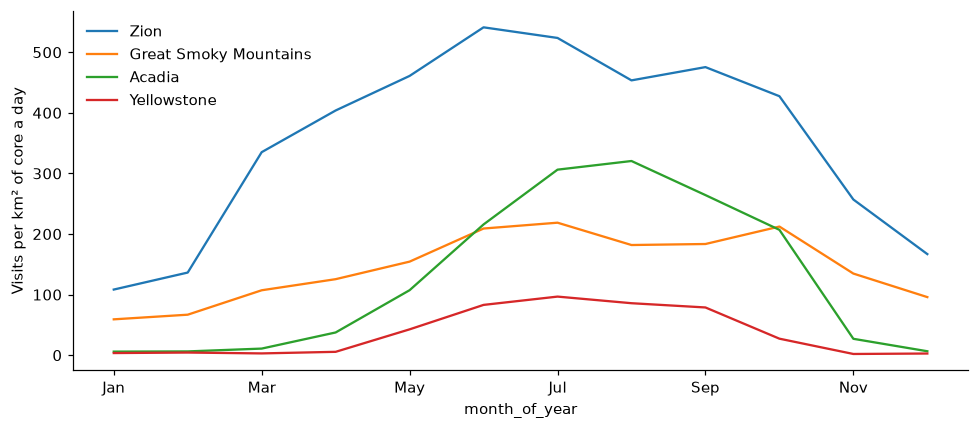

In [5]:
s = m[m.year <= 2024].groupby(['park', 'month_of_year']).visits_per_km2_core_per_day.mean().unstack()
order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
four = s.loc[['Zion', 'Great Smoky Mountains', 'Acadia', 'Yellowstone'], order]
print(four.round(0).to_string())
four.T.plot(figsize=(9, 4), ylabel='Visits per km² of core a day'); plt.legend(frameon=False); plt.tight_layout()

## 4. Zion's core, mapped

Text(0.5, 1.0, 'Zion: core 33.2 km² of 602 km² (simplified shapes)')

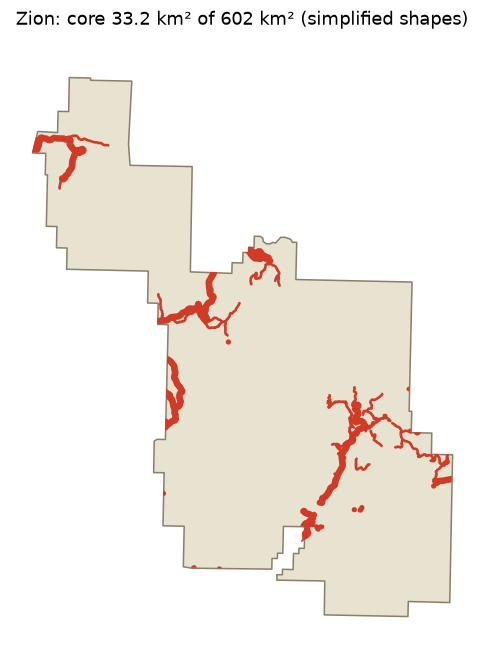

In [6]:
parks = gpd.read_file(f'{DATA}/geometry/parks.geojson'); cores = gpd.read_file(f'{DATA}/geometry/cores.geojson')
z = parks[parks.key == 'ZION'].to_crs(32612); zc = cores[cores.key == 'ZION'].to_crs(32612)
ax = z.plot(color='#e8e2d0', edgecolor='#8a7f68', figsize=(7, 7)); zc.plot(ax=ax, color='#cf3b26')
ax.set_axis_off(); ax.set_title(f"Zion: core {zc.area.sum() / 1e6:.1f} km² of {z.area.sum() / 1e6:.0f} km² (simplified shapes)")

## 5. Check against Plotlay's export

In [7]:
print(sorted(cores.key) == sorted(p.unit_code), 'every core keyed to a park;', len(cores), 'cores')

True every core keyed to a park; 25 cores


## Read it carefully

- **Counting methods vary by park** and change over time (traffic counters and per-vehicle multipliers in each park's
  counting instructions). A jump between years can be a new method.
- **The cores are drawn estimates**: one written rule over NPS's mapped roads, trails and facilities, not measured
  footprints. Areas from the simplified shapes here differ slightly from the tables, which use the full shapes.
- **Visits are not unique people.** Re-entries count again.
- **Closures**: April 2020, Death Valley in September 2023 after the floods, and the shutdown of October and November
  2025, whose figures may still change.